In [4]:
import pandas as pd 

In [5]:
import sys
print(sys.executable)

/home/aryan/hiv-latency-sc/.venv/bin/python


In [6]:
meta = pd.read_csv('/scratch/maid/DP2_PBMC/PBMC_rawData/MetaData.csv')

print(meta.shape)
print(meta.columns.tolist())
meta.head()

(35, 9)
['Admera ID', 'UniqID', 'Client Sample ID', 'Wk', '#genes', '#cells', '#Fragt', 'Group', 'Batch']


,Admera ID,UniqID,Client Sample ID,Wk,#genes,#cells,#Fragt,Group,Batch
0,24155-06-10,DEAB_Wk16,DEAB,Wk16,684,9350,7928,EarlyART,1
1,24155-06-09,DEG2_Wk16,DEG2,Wk16,760,8341,4783,EarlyART,1
2,24155-06-08,DEL5_Wk16,DEL5,Wk16,571,5188,6622,EarlyART,1
3,24155-06-07,KI6_Wk16,KI6,Wk16,65,4254,6283,EarlyART,1
4,24155-06-06,KPN_Wk16,KPN,Wk16,44,12809,5875,EarlyART,1


In [7]:
print("Animals:", meta['Client Sample ID'].nunique())
print(sorted(meta['Client Sample ID'].unique()))

print('\nTimepoints:', meta['Wk'].nunique())
print(meta['Wk'].value_counts().sort_index())

print('\nGroups:')
print(meta['Group'].value_counts())

print('\nbatches:')
print(meta['Batch'].value_counts())

Animals: 7
['DEAB', 'DEG2', 'DEL5', 'KI6', 'KPN', 'PZB', 'T623']

Timepoints: 9
Wk
Wk0      7
Wk136    3
Wk16     5
Wk192    5
Wk240    1
Wk304    4
Wk4      2
Wk72     7
Wk8      1
Name: count, dtype: int64

Groups:
Group
LateART     13
EarlyART     8
MidART       7
PreART       7
Name: count, dtype: int64

batches:
Batch
1    24
2    11
Name: count, dtype: int64


In [8]:
print("Animal x Group:")
print(pd.crosstab(meta['Client Sample ID'], meta['Group']))

print("\nGroup x Batch:")
print(pd.crosstab(meta['Group'], meta['Batch']))

Animal x Group:
Group             EarlyART  LateART  MidART  PreART
Client Sample ID                                   
DEAB                     2        3       1       1
DEG2                     1        2       1       1
DEL5                     1        2       1       1
KI6                      1        2       1       1
KPN                      1        2       1       1
PZB                      1        1       1       1
T623                     1        1       1       1

Group x Batch:
Batch      1  2
Group          
EarlyART   5  3
LateART   10  3
MidART     4  3
PreART     5  2


In [9]:
print("Raw total cells:", meta['#cells'].sum())

Raw total cells: 301872


In [10]:
import scanpy as sc
import pandas as pd
import os

base = '/scratch/maid/DP2_PBMC/PBMC_rawData/'
meta = pd.read_csv(f"{base}/MetaData.csv")

mito_genes = ['ND1','ND2','ND3','ND4','ND4L','ND5','ND6', 
             'COX1','COX2','COX3','ATP6','ATP8','CYTB']

def load_one_sample(row):
    uniq = row['UniqID']
    path = f'{base}/{uniq}/filtered_feature_bc_matrix.h5'
    if not os.path.exists(path):
        print(F"Missing. . . {path}")
        return None
    a = sc.read_10x_h5(path)
    a.var_names_make_unique()

    a.var['mt'] = a.var_names.isin(mito_genes)

    sc.pp.calculate_qc_metrics(a, qc_vars='mt', percent_top=None, log1p=False, inplace=True)

    #attaching metadata to every label
    a.obs['sample'] = uniq
    a.obs['animal'] = row['Client Sample ID']
    a.obs['week'] = row['Wk']
    a.obs['group'] = row['Group']
    a.obs['batch'] = row['Batch']

    a.obs_names = [f"{uniq}_{bc}" for bc in a.obs_names]
    print(f"   {uniq}: {a.n_obs} cells, {a.var['mt'].sum()} mito genes")
    return a

In [11]:
sample_ros = meta[meta['UniqID'].isin(['DEL5_Wk0', 'KI6_Wk0', 'DEG2_Wk0'])]
sample_adatas = [load_one_sample(row) for _, row in sample_ros.iterrows()]

/home/aryan/hiv-latency-sc/.venv/lib/python3.12/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


   DEG2_Wk0: 10250 cells, 13 mito genes


/home/aryan/hiv-latency-sc/.venv/lib/python3.12/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


   DEL5_Wk0: 13075 cells, 13 mito genes
   KI6_Wk0: 14967 cells, 13 mito genes


/home/aryan/hiv-latency-sc/.venv/lib/python3.12/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


In [12]:
# all 35 samples
all_adata = []
for _, row in meta.iterrows():
    a = load_one_sample(row)
    if a is not None:
        all_adata.append(a)

print(f"\nLoaded {len(all_adata)} samples successfully")

# Concatenating into one object
adata_all = sc.concat(all_adata, join='inner', index_unique=None)
adata_all.obs_names_make_unique()  
print(adata_all)

/home/aryan/hiv-latency-sc/.venv/lib/python3.12/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


   DEAB_Wk16: 9350 cells, 13 mito genes


/home/aryan/hiv-latency-sc/.venv/lib/python3.12/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


   DEG2_Wk16: 8341 cells, 13 mito genes


/home/aryan/hiv-latency-sc/.venv/lib/python3.12/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


...

   PZB_Wk72: 5138 cells, 13 mito genes


/home/aryan/hiv-latency-sc/.venv/lib/python3.12/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


   PZB_Wk0: 5715 cells, 13 mito genes


/home/aryan/hiv-latency-sc/.venv/lib/python3.12/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


   T623_Wk0: 8081 cells, 13 mito genes

Loaded 35 samples successfully
AnnData object with n_obs × n_vars = 301872 × 26530
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'sample', 'animal', 'week', 'group', 'batch'
    layers: None (.X)


In [13]:
os.makedirs('/home/aryan/hiv-latency-sc/objects', exist_ok=True)

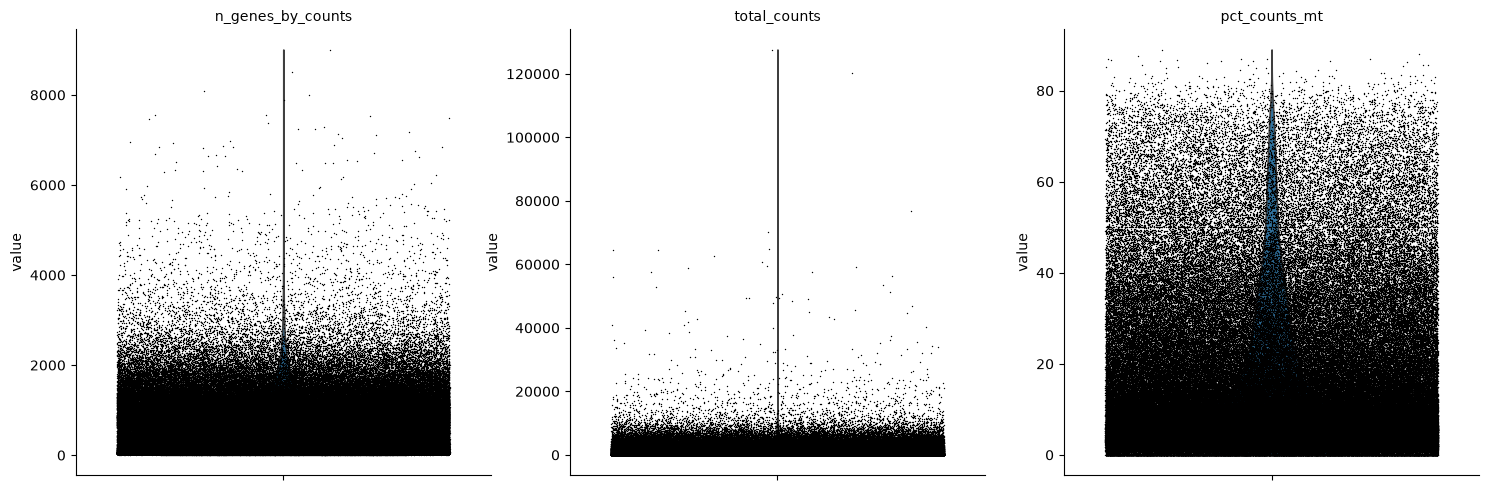

In [14]:
sc.pl.violin(adata_all, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'], jitter=0.4, multi_panel=True)

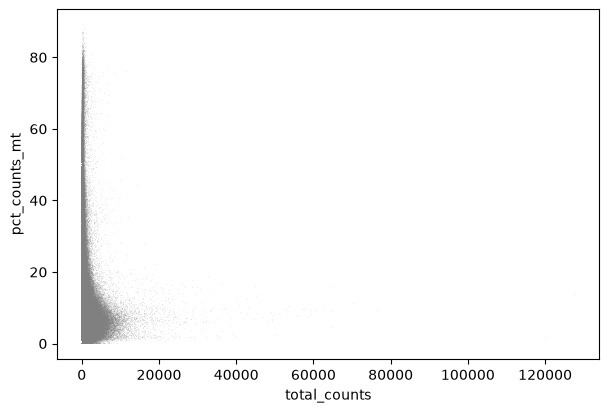

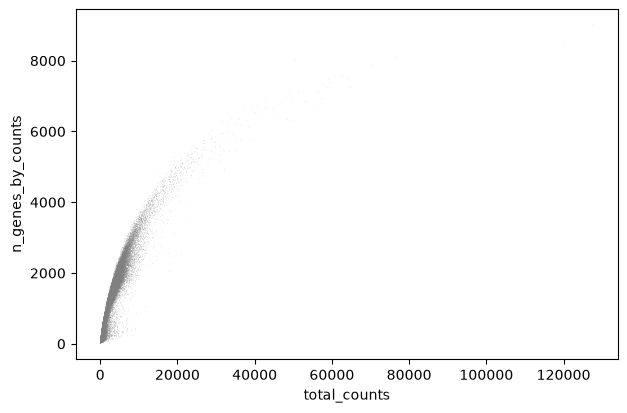

In [15]:
sc.pl.scatter(adata_all, x='total_counts', y='pct_counts_mt')
sc.pl.scatter(adata_all, x='total_counts', y='n_genes_by_counts')

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns


SAMPLE_COL = "sample"
assert SAMPLE_COL in adata_all.obs, (
    f"{SAMPLE_COL!r} not in adata_all.obs; available: {list(adata_all.obs.columns)}"
)
 
obs = adata_all.obs
n_total = adata_all.n_obs
print(f"{n_total:,} cells across {obs[SAMPLE_COL].nunique()} samples")

301,872 cells across 35 samples


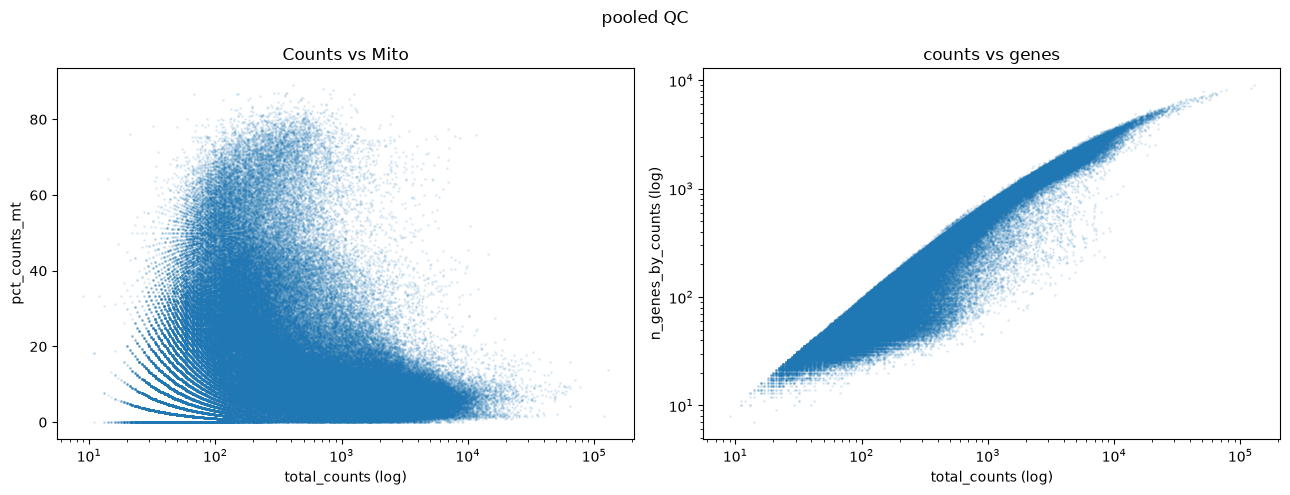

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(obs['total_counts'], obs['pct_counts_mt'],
                s=1, alpha=0.1, rasterized=True)
axes[0].set_xscale("log")
axes[0].set(xlabel="total_counts (log)", ylabel="pct_counts_mt",
            title="Counts vs Mito")

axes[1].scatter(obs['total_counts'], obs['n_genes_by_counts'],
                s=1, alpha=0.1, rasterized=True)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set(xlabel="total_counts (log)", ylabel="n_genes_by_counts (log)",
            title="counts vs genes")

fig.suptitle("pooled QC")
plt.tight_layout()
plt.show()

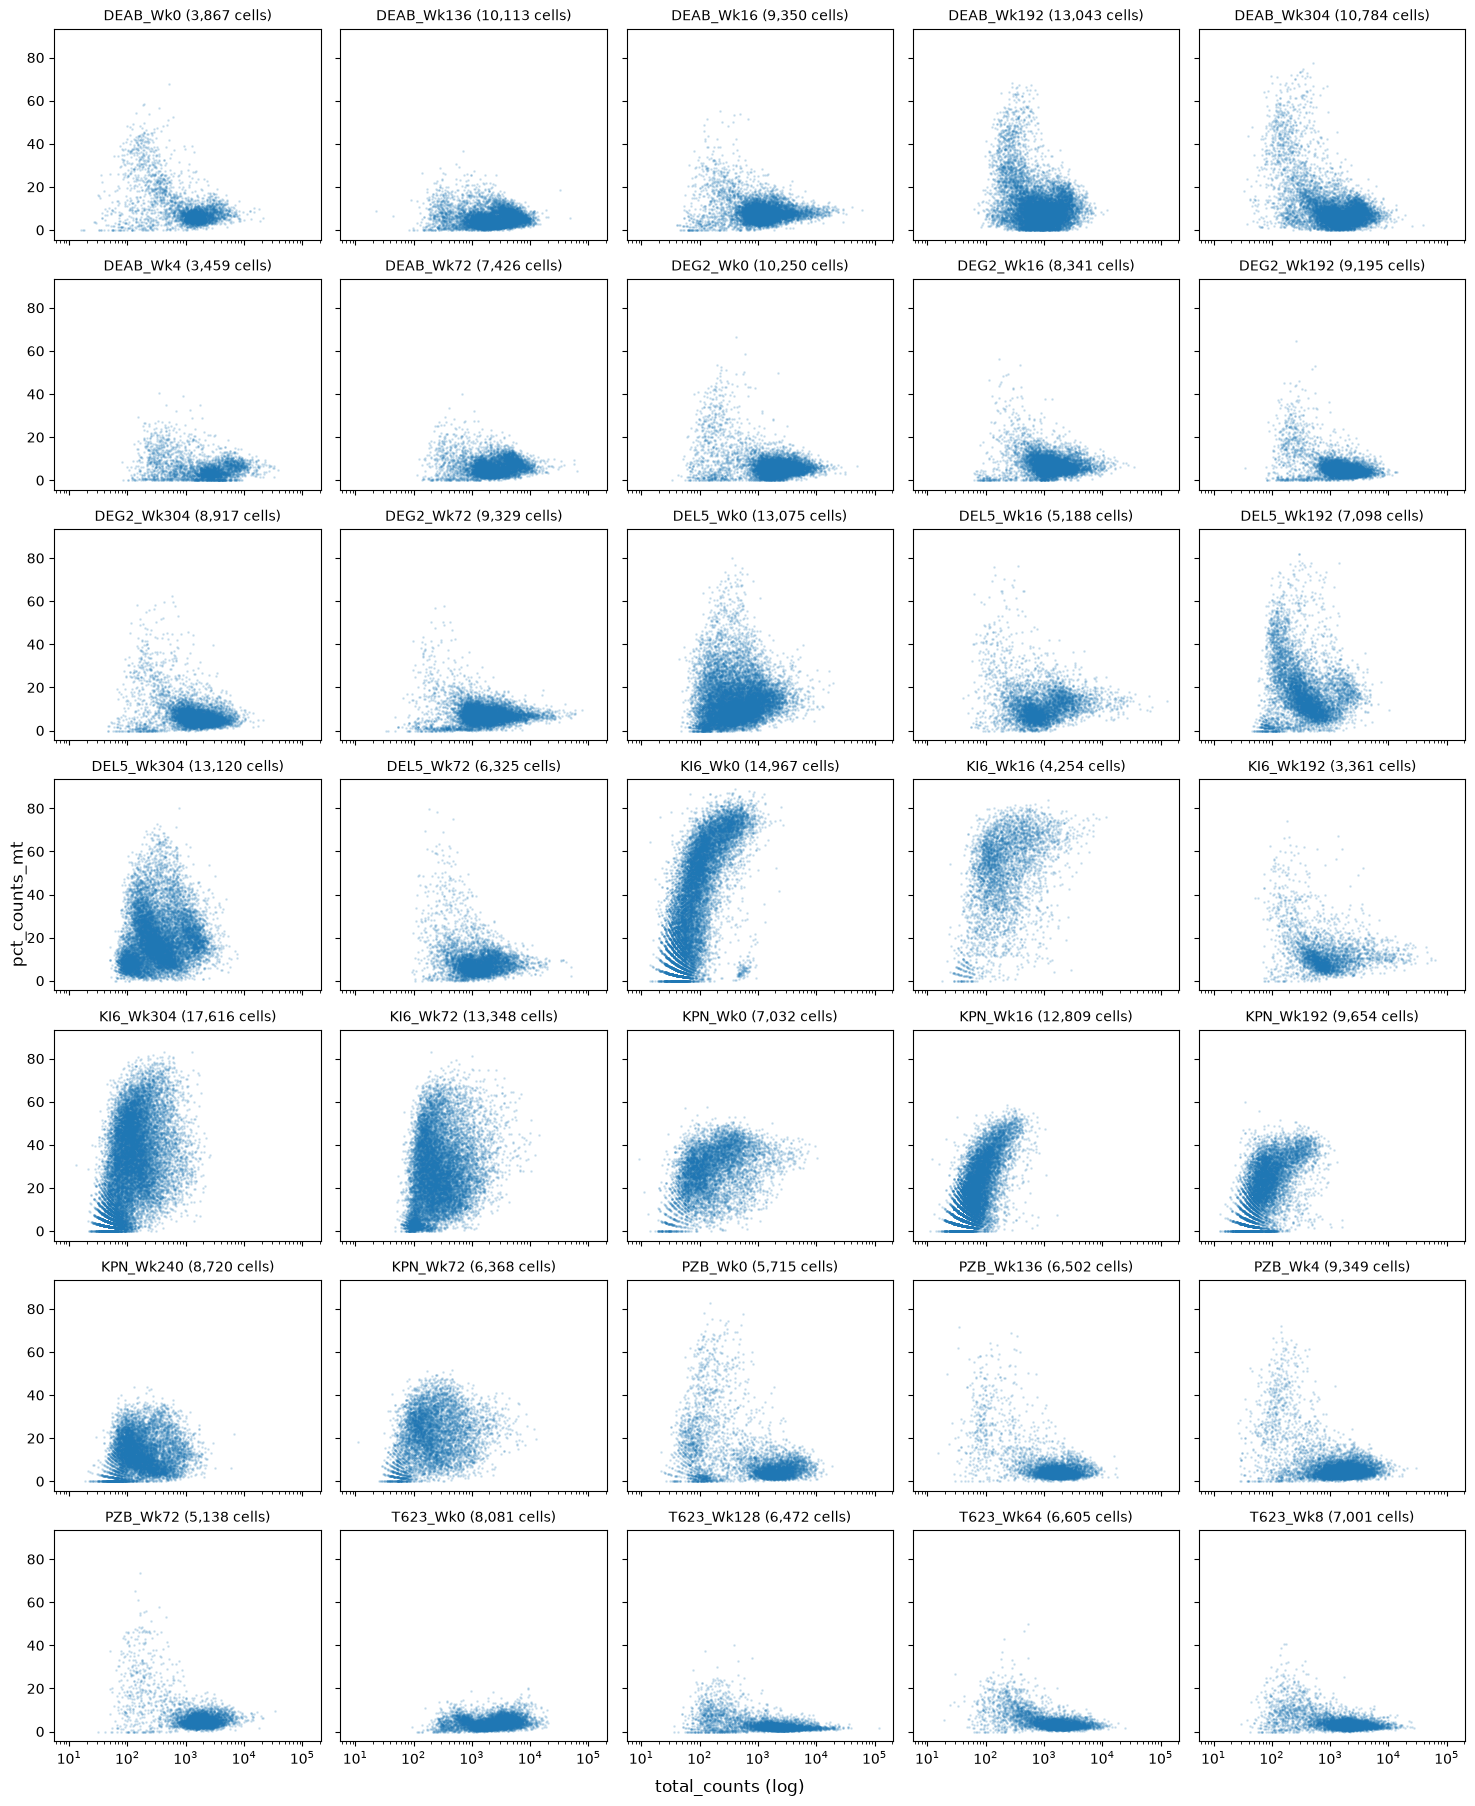

In [18]:
import numpy as np

#per sample (count vs mito, log-x)
samples = sorted(obs[SAMPLE_COL].unique())
ncol = 5
nrow = int(np.ceil(len(samples) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3 * ncol, 2.6 * nrow),
                         sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()

for ax, s in zip(axes, samples):
    d = obs[obs[SAMPLE_COL] == s]
    ax.scatter(d['total_counts'], d['pct_counts_mt'],
               s=1, alpha=0.15, rasterized=True)
    ax.set_xscale("log")
    ax.set_title(f"{s} ({len(d):,} cells)", fontsize=10)

for ax in axes[len(samples):]:
    ax.axis='off'

fig.supxlabel("total_counts (log)")
fig.supylabel("pct_counts_mt")
plt.tight_layout()
plt.show()

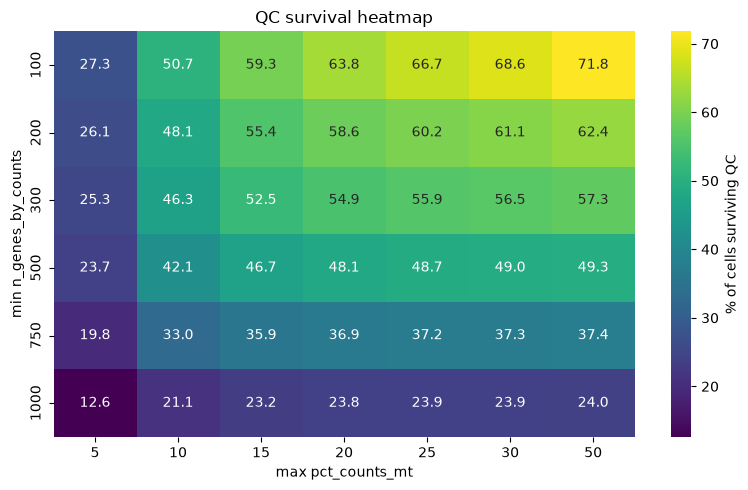

The no. of cells surviving QC:
         5       10      15      20      25      30      50
100   82440  153132  179151  192726  201206  206981  216743
200   78662  145278  167301  176876  181732  184564  188473
300   76372  139805  158605  165609  168858  170660  172841
500   71589  127239  140829  145255  147136  148068  148884
750   59666   99491  108445  111309  112183  112533  112816
1000  38079   63809   70081   71728   72082   72219   72344


In [19]:
# min_genes x max_mito grid
min_genes = [100, 200, 300, 500, 750, 1000]
max_mito = [5, 10, 15, 20, 25, 30, 50]

g = obs['n_genes_by_counts'].to_numpy()
m = obs['pct_counts_mt'].to_numpy()

surv = pd.DataFrame(index=min_genes, columns=max_mito, dtype=float)
for mg in min_genes:
    for mm in max_mito:
        surv.loc[mg, mm] = int(((g >= mg) & (m <= mm)).sum())

surv_pct = surv / n_total * 100

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(surv_pct, annot=True, fmt=".1f", cmap="viridis",
            cbar_kws={"label": "% of cells surviving QC"}, ax=ax)
ax.set(xlabel="max pct_counts_mt", ylabel="min n_genes_by_counts",
       title="QC survival heatmap")

plt.tight_layout()
plt.show()

print("The no. of cells surviving QC:")
print(surv.astype(int))

In [20]:
# trying to estimate the per sample bleed at a few thresholds
cand = [(200, 20), (300, 15), (500, 10)]

cols = []
for mg, mm in cand:
    keep = (obs['n_genes_by_counts'] >= mg) & (obs['pct_counts_mt'] <= mm)
    ret = obs.assign(_keep=keep).groupby(SAMPLE_COL)["_keep"].mean().mul(100).round(1)
    ret.name = f"g>={mg}, mt<={mm}"
    cols.append(ret)


bleed = pd.concat(cols, axis=1)
bleed.insert(0, "n_cells", obs.groupby(SAMPLE_COL).size())
bleed = bleed.sort_values(bleed.columns[1])

print("\nPer sample retained %")
print(bleed.to_string())


Per sample retained %
            n_cells  g>=200, mt<=20  g>=300, mt<=15  g>=500, mt<=10
sample                                                             
KPN_Wk16      12809             0.1             0.0             0.0
KPN_Wk192      9654             0.2             0.0             0.0
KI6_Wk0       14967             0.7             0.7             0.3
KI6_Wk16       4254             1.3             0.4             0.1
KI6_Wk304     17616             1.9             0.4             0.0
KPN_Wk0        7032             3.1             1.0             0.1
KPN_Wk72       6368            13.1             5.2             1.0
KI6_Wk72      13348            13.3             4.4             0.5
KPN_Wk240      8720            20.9            10.1             1.8
DEL5_Wk304    13120            31.9            14.2             2.8
DEL5_Wk192     7098            48.7            28.2             8.0
DEL5_Wk0      13075            56.9            32.9             7.9
PZB_Wk0        5715      